<a href="https://colab.research.google.com/github/dipalimhapsekar/CSL701-CE-28_Machine-Learning-Lab/blob/main/ML_Experiment_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 10


Student Name :Dipali Manohar Mhapsekar

Batch :CE02


Roll Number :ce28



### **Aim**

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import urllib.request
import os

# URL of the dataset
url = "https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Mall_Customers.csv"
csv_path = "Mall_Customers.csv"

# Download the file if it doesn't exist locally
if not os.path.exists(csv_path):
    print("Downloading Mall_Customers.csv...")
    urllib.request.urlretrieve(url, csv_path)

# Load the dataset
df = pd.read_csv(csv_path)

# Display basic information and the first 5 rows
print(df.info())
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

In [4]:
# Task 2: Feature Selection and Standardization
# Selecting Annual Income (k$) and Spending Score (1-100)
features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df[features].values

# Initializing and applying StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Shape of scaled features:", X_scaled.shape)
print("First 5 scaled rows:\n", X_scaled[:5])

# Task 2: Verify the distribution of scaled features
scaled_df = pd.DataFrame(X_scaled, columns=features)
print("\nMean of scaled features (Should be approx 0):")
print(scaled_df.mean())
print("\nStandard Deviation of scaled features (Should be approx 1):")
print(scaled_df.std())

Shape of scaled features: (200, 2)
First 5 scaled rows:
 [[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]

Mean of scaled features (Should be approx 0):
Annual Income (k$)       -2.131628e-16
Spending Score (1-100)   -1.465494e-16
dtype: float64

Standard Deviation of scaled features (Should be approx 1):
Annual Income (k$)        1.002509
Spending Score (1-100)    1.002509
dtype: float64


# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

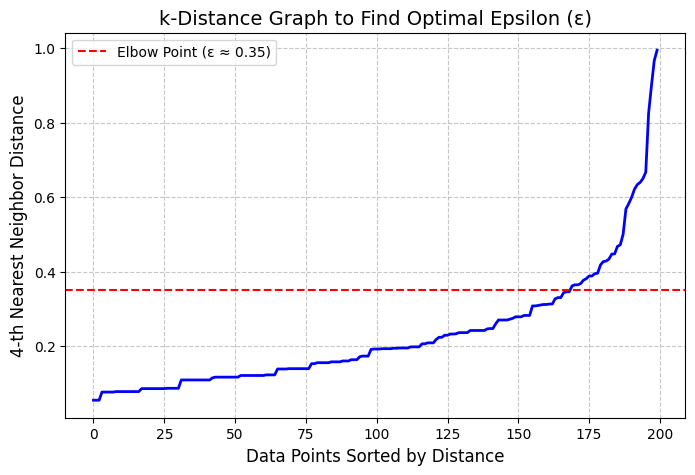

In [6]:
# Task 3: Hyperparameter Selection via k-Distance Graph
# We will use min_samples = 4 (typical for 2D data), so we calculate distance to the 4th nearest neighbor (index 3)
k = 4
neigh = NearestNeighbors(n_neighbors=k)
nbrs = neigh.fit(X_scaled)
distances, indices = nbrs.kneighbors(X_scaled)

# Sort distance to the k-th nearest neighbor
k_distances = np.sort(distances[:, k-1])

# Plot the k-distance graph
plt.figure(figsize=(8, 5))
plt.plot(k_distances, color='blue', lw=2)
plt.title('k-Distance Graph to Find Optimal Epsilon (ε)', fontsize=14)
plt.xlabel('Data Points Sorted by Distance', fontsize=12)
plt.ylabel(f'{k}-th Nearest Neighbor Distance', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# Adding a line to highlight the elbow point (around distance ~0.35)
plt.axhline(y=0.35, color='red', linestyle='--', label='Elbow Point (ε ≈ 0.35)')
plt.legend()
plt.show()

# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

In [8]:
# Task 4: Implement DBSCAN Clustering
# Instantiating DBSCAN with selected epsilon (0.35) and min_samples (4)
epsilon = 0.35
min_samples = 4

dbscan = DBSCAN(eps=epsilon, min_samples=min_samples)
dbscan.fit(X_scaled)

# Get cluster assignments and labels
# Labels of -1 indicate noise points (outliers)
labels = dbscan.labels_

# Print unique labels to see how many clusters were formed
print("Unique cluster labels generated:", np.unique(labels))
print("Number of points assigned to each label:")
print(pd.Series(labels).value_counts())

Unique cluster labels generated: [-1  0  1  2  3  4  5  6]
Number of points assigned to each label:
 3    89
 4    32
 5    23
 0    17
-1    16
 1    12
 2     7
 6     4
Name: count, dtype: int64


# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

In [10]:
# Task 5: Evaluate DBSCAN Clustering

# 1. Number of clusters formed (excluding noise)
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)

# 2. Number of noise points
n_noise_ = list(labels).count(-1)

# 3. Calculate Silhouette Score
# Note: Silhouette score cannot be calculated with only noise/1 cluster, and noise points are excluded from evaluation
non_noise_mask = labels != -1
if n_clusters_ > 1:
    score = silhouette_score(X_scaled[non_noise_mask], labels[non_noise_mask])
else:
    score = "N/A (Not enough clusters)"

print(f"Estimated number of clusters: {n_clusters_}")
print(f"Estimated number of noise points: {n_noise_} ({100 * n_noise_ / len(labels):.1f}% of dataset)")
print(f"Silhouette Score (excluding noise): {score:.4f}")

Estimated number of clusters: 7
Estimated number of noise points: 16 (8.0% of dataset)
Silhouette Score (excluding noise): 0.5110


# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

Cluster Statistics (Mean and Count):


Annual Income (k$)       Spending Score (1-100)      
                      mean count                   mean count
Cluster                                                      
-1               93.250000    16              65.812500    16
 0               25.235294    17              76.352941    17
 1               24.583333    12               9.583333    12
 2               22.428571     7              34.428571     7
 3               55.022472    89              48.325843    89
 4               80.500000    32              82.562500    32
 5               80.956522    23              12.782609    23
 6              101.000000     4              24.000000     4

/tmp/ipykernel_1095/3066375179.py:16: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap('tab10', len(unique_labels))
/tmp/ipykernel_1095/3066375179.py:33: UserWarning: You passed a edgecolor/edgecolors ('none') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(


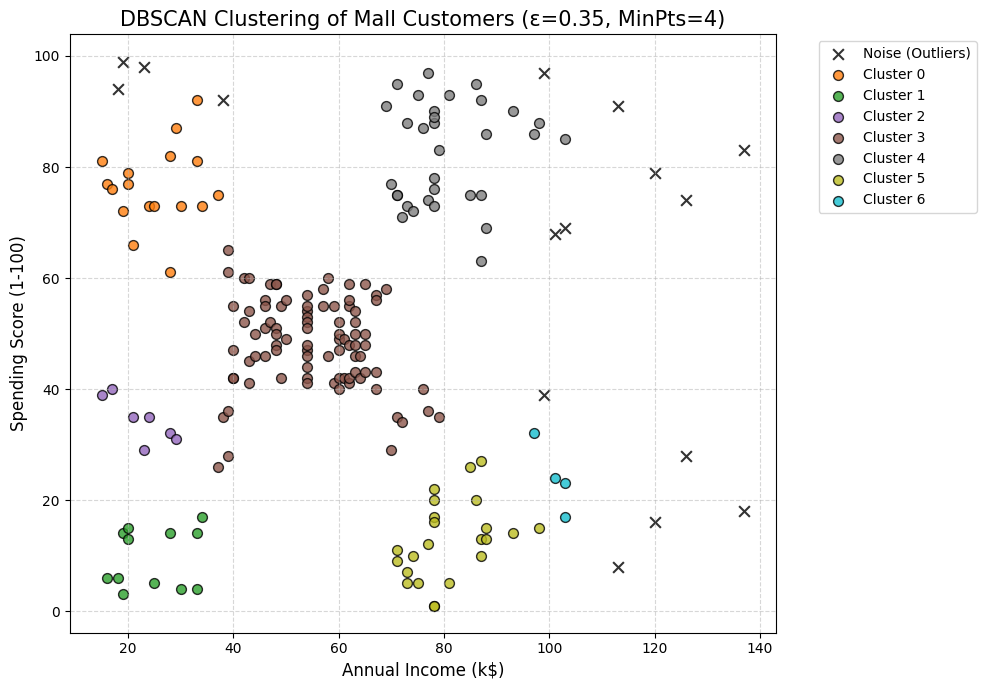

In [12]:
# Task 6: Analyze Results and Cluster Statistics

# 1. Append cluster labels back to the original DataFrame
df['Cluster'] = labels

# 2. Calculate average statistics per cluster
cluster_stats = df.groupby('Cluster')[['Annual Income (k$)', 'Spending Score (1-100)']].agg(['mean', 'count'])
print("Cluster Statistics (Mean and Count):")
display(cluster_stats)

# 3. Visualize the DBSCAN clusters and noise points
plt.figure(figsize=(10, 7))

# Generate a color palette for the clusters
unique_labels = np.unique(labels)
colors = plt.cm.get_cmap('tab10', len(unique_labels))

for i, label in enumerate(unique_labels):
    if label == -1:
        # Outliers/Noise plotted in black with 'x' marker
        color = 'black'
        marker = 'x'
        label_name = 'Noise (Outliers)'
        size = 60
    else:
        color = colors(i)
        marker = 'o'
        label_name = f'Cluster {label}'
        size = 50

    # Select points belonging to the current cluster
    member_mask = (labels == label)
    plt.scatter(
        df.loc[member_mask, 'Annual Income (k$)'],
        df.loc[member_mask, 'Spending Score (1-100)'],
        color=color,
        marker=marker,
        s=size,
        edgecolor='k' if marker == 'o' else 'none',
        label=label_name,
        alpha=0.8
    )

plt.title('DBSCAN Clustering of Mall Customers (ε=0.35, MinPts=4)', fontsize=15)
plt.xlabel('Annual Income (k$)', fontsize=12)
plt.ylabel('Spending Score (1-100)', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.